In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data_df = pd.read_csv('cleaned_dataset.csv')
data_df['country'].value_counts().head(10)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [2]:
# Calculate total content by country.
country_df = data_df.assign(
    country=data_df['country'].str.split(',')).explode('country')
country_df['country'] = country_df['country'].str.strip()
country_df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
country_counts = country_df[
    country_df['country'] != 'Unknown'
]['country'].value_counts().head(10)
country_counts

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

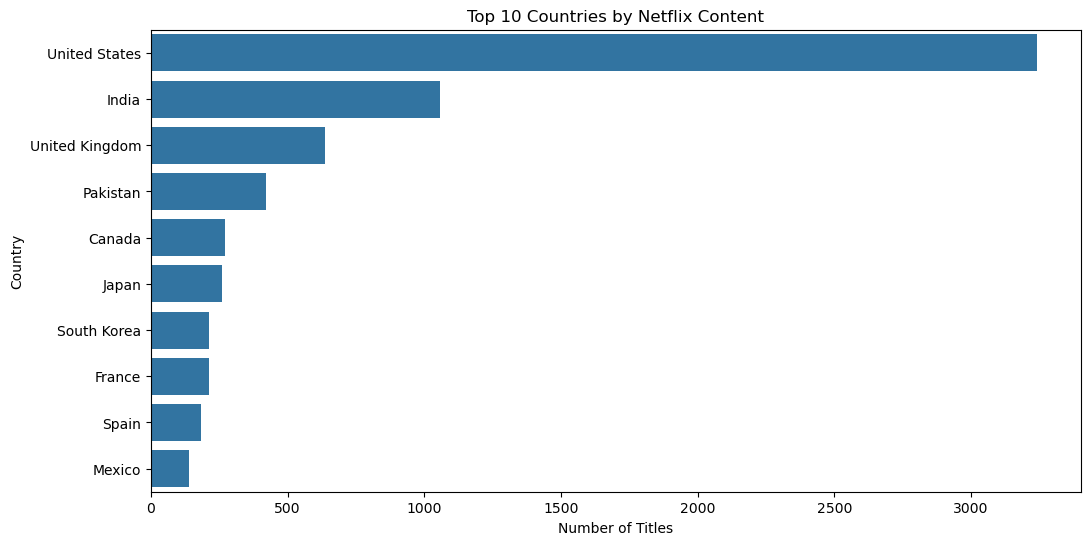

In [4]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

In [5]:
# Generate country-wise ranking report.
country_report = country_counts.reset_index()
country_report.columns = ['Country', 'Total_Content']
country_report['Rank'] = range(1, len(country_report) + 1)
country_report = country_report[['Rank', 'Country', 'Total_Content']]
country_report

,Rank,Country,Total_Content
0,1,United States,3240
1,2,India,1057
2,3,United Kingdom,638
3,4,Pakistan,421
4,5,Canada,271
5,6,Japan,259
6,7,South Korea,214
7,8,France,213
8,9,Spain,182
9,10,Mexico,138


In [6]:
country_report.to_csv('country_wise_analysis.csv', index=False)

## Key Findings – Country-Wise Netflix Content Analysis

1. The United States leads with 3,240 titles.
2. India ranks second with 1,057 titles.
3. The United Kingdom ranks third with 638 titles.
4. Pakistan ranks fourth with 421 titles.
5. Mexico appears in the top 10 with 138 titles.

### Conclusion
The United States contributes the largest amount of Netflix content in this dataset, followed by India and the United Kingdom. This indicates a strong representation of content from these countries.